In [38]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt
import cmocean

### Load Ross Island region bounds

In [39]:
# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

## Load raw Bedmap123 data points

In [40]:
REDO_CROP = False

if REDO_CROP:
    path_to_bedmap123 = "/Users/kim.bente/DATA/bedmap_raw_data/bedmap123.csv"
    bedmap123 = pd.read_csv(path_to_bedmap123, dtype = {"trajectory_id": str})

    bedmap123_ross_island = bedmap123[
        (bedmap123["x"] >= x_min) & (bedmap123["x"] <= x_max) & (bedmap123["y"] >= y_min) & (bedmap123["y"] <= y_max)]

    # Save subset
    destination_path = "/Users/kim.bente/DATA/bedmap_raw_data/bedmap123_regional/bedmap123_ross_island.csv"
    bedmap123_ross_island.to_csv(destination_path, index = False)

else:
    # Load pre-cropped data
    path_to_bedmap123_ross_island = "/Users/kim.bente/DATA/bedmap_raw_data/bedmap123_regional/bedmap123_ross_island.csv"
    bedmap123_ross_island = pd.read_csv(path_to_bedmap123_ross_island, dtype = {"trajectory_id": str})

print(f"Loaded bedmap123_ross_island with {len(bedmap123_ross_island)} rows.")
bedmap123_ross_island.head()

# Note: previously from "data/bedmap123_ross_onshelf_3M.csv"

Loaded bedmap123_ross_island with 281925 rows.


,lon,lat,x,y,s,t,b,b_inferred,source,trajectory_id,trace_id
0,170.1333,-78.41167,216463.844340,-1.244552e+06,54.0,320.0,-815.0,False,BEDMAP1_1966-2000_AIR_BM1.csv,296,-9999
1,169.1833,-78.13333,242801.567307,-1.270798e+06,35.0,218.0,-920.0,False,BEDMAP1_1966-2000_AIR_BM1.csv,297,-9999
2,168.9500,-78.07500,249201.416991,-1.276084e+06,31.0,156.0,-902.0,False,BEDMAP1_1966-2000_AIR_BM1.csv,298,-9999
3,168.6667,-78.01000,256910.452033,-1.281834e+06,23.0,123.0,-887.0,False,BEDMAP1_1966-2000_AIR_BM1.csv,299,-9999
4,168.3667,-77.96667,264577.987681,-1.285131e+06,26.0,111.0,-836.0,False,BEDMAP1_1966-2000_AIR_BM1.csv,300,-9999


## Visualise raw data

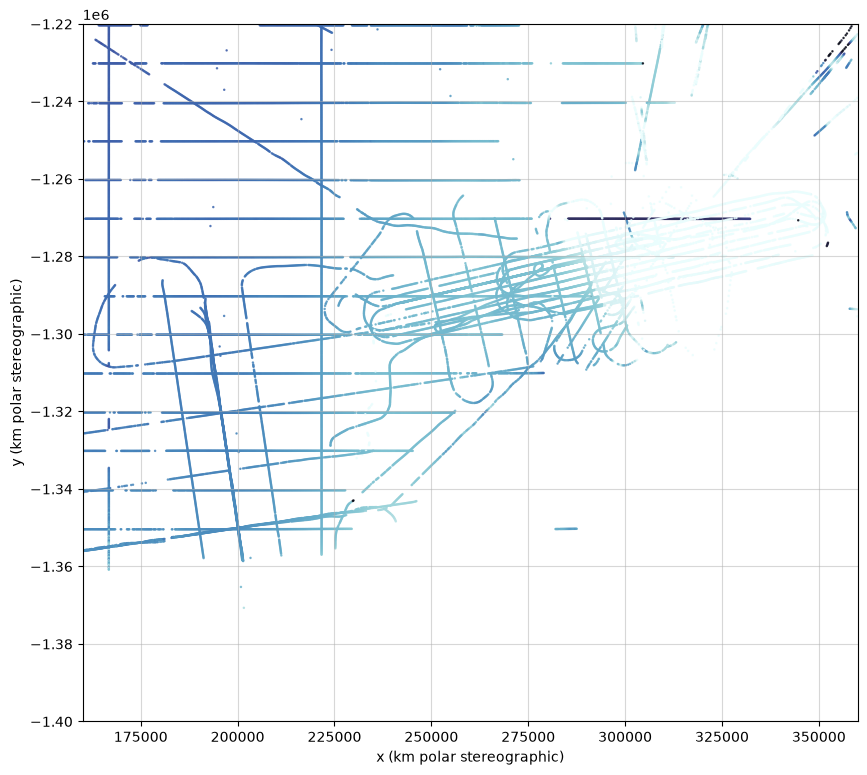

In [41]:
SUBSETTER = 10
fig, ax = plt.subplots(figsize = (10, 10))

# 2) thickness on top (draw second)
ax.scatter(
    bedmap123_ross_island['x'][::SUBSETTER], 
    bedmap123_ross_island['y'][::SUBSETTER], 
    c = bedmap123_ross_island['t'][::SUBSETTER], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

# Preprocessing step 1: Firn correction

Applying a universal firn correction of 10m.

In [42]:
# Load meta data which contains firn adjustment info
# TODO replace with path
meta = pd.read_csv("/Users/kim.bente/DATA/bedmap_raw_data/bedmap123_metadata.csv")

# Extract float
meta["firn_correction"] = meta.firn.str.extract(r"([-+]?\d*\.?\d+)").astype(float)
# Replace -9999 with 0.0 (We assume this means "zero" adjustment applied so far.)
meta["firn_correction"] = meta["firn_correction"].replace(-9999, 0.0)
# Calculate remaining delta (we correct all data to have a firn correction of 10)
# t_corrected = t_observed - 10

UNIVERSAL_FIRN_CORRECTION = 10.0
meta["firn_correction_delta"] = meta["firn_correction"] - UNIVERSAL_FIRN_CORRECTION

# Create lookup dictionary from meta
firn_delta_lookup = dict(zip(meta["source"], meta["firn_correction_delta"]))

# Add the correction delta to the thickness points
# NOTE: Create fa (firn adjusted) variable
bedmap123_ross_island["t_fa"] = (
    bedmap123_ross_island["t"] + bedmap123_ross_island["source"].map(firn_delta_lookup)
)

bedmap123_ross_island["t_fa"].describe()

count    281925.000000
mean        182.906332
std         109.917610
min         -10.000000
25%         132.671895
50%         171.814060
75%         272.400000
max        2154.640000
Name: t_fa, dtype: float64

# Preprocessing step 2: Keep only on-shelf points

We use the phase-based ice velocity dataset for the mask.

### Load phase-based ice velocity

In [43]:
path_to_phase_based_ice_vel = "/Users/kim.bente/DATA/ice_velocity/NSIDC-0484_2-20261004_220442/antarctica_ice_velocity_450m_v2.nc"

ice_vel_phase = xr.open_dataset(path_to_phase_based_ice_vel)
# print(ice_vel_phase)  # shows variables, dimensions and coordinates

# Subset for Ross Island region
ice_vel_phase_ross_island = ice_vel_phase.sel(
    x = slice(x_min, x_max),
    y = slice(y_max, y_min) # Note: y_max and y_min are reversed because y decreases southward in polar stereographic coordinates
)

# free memory
del ice_vel_phase 

print(ice_vel_phase_ross_island)  # shows variables, dimensions and coordinates

<xarray.Dataset> Size: 8MB
Dimensions:       (y: 400, x: 445)
Coordinates:
  * y             (y) float64 3kB -1.22e+06 -1.221e+06 ... -1.399e+06 -1.4e+06
  * x             (x) float64 4kB 1.601e+05 1.606e+05 ... 3.594e+05 3.599e+05
    lat           (y, x) float64 1MB ...
    lon           (y, x) float64 1MB ...
Data variables:
    coord_system  |S1 1B ...
    VX            (y, x) float32 712kB ...
    VY            (y, x) float32 712kB ...
    STDX          (y, x) float32 712kB ...
    STDY          (y, x) float32 712kB ...
    ERRX          (y, x) float32 712kB ...
    ERRY          (y, x) float32 712kB ...
    CNT           (y, x) int32 712kB ...
Attributes: (12/26)
    Conventions:               CF-1.6
    Metadata_Conventions:      CF-1.6, Unidata Dataset Discovery v1.0, GDS v2.0
    standard_name_vocabulary:  CF Standard Name Table (v22, 12 February 2013)
    id:                        vel_nsidc.CF16.nc
    title:                     MEaSURES Antarctica Ice Velocity Map 450m spac

In [44]:
# Calculate ice speed (magnitude of VX and VY) and add it as a new variable to the dataset
ice_vel_phase_ross_island["SPEED"] = np.hypot(ice_vel_phase_ross_island["VX"], ice_vel_phase_ross_island["VY"])
ice_vel_phase_ross_island["SPEED"].attrs = {
    "long_name": "Ice speed (magnitude of VX and VY)",
    "units": ice_vel_phase_ross_island["VX"].attrs.get("units", "m/yr"),
}

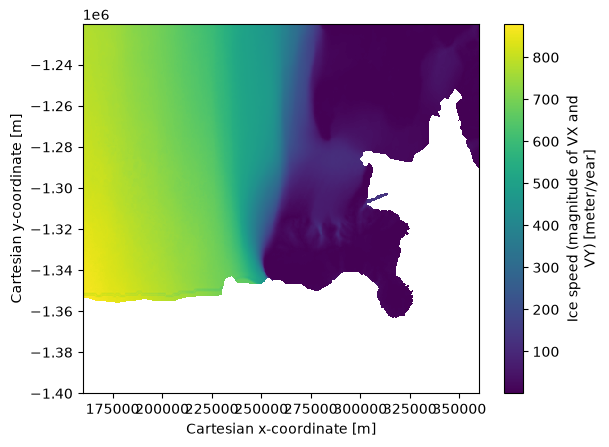

In [45]:
ice_vel_phase_ross_island["SPEED"].plot()

### Look up closes ice velocity value

In [46]:
# Interpolate 280k points
# Takes 11 seconds
vel_at_points = ice_vel_phase_ross_island[["VX", "VY"]].interp(
    x = ("points", bedmap123_ross_island["x"].values),
    y = ("points", bedmap123_ross_island["y"].values),
    method = "linear",
)

# Add to dataset
bedmap123_ross_island["VX"] = vel_at_points["VX"].values
bedmap123_ross_island["VY"] = vel_at_points["VY"].values

# Calculate ice speed now for consistency (matching VX and VY)
bedmap123_ross_island["SPEED"] = np.hypot(bedmap123_ross_island["VX"], bedmap123_ross_island["VY"])

print("Number of NaN values in SPEED column:", bedmap123_ross_island["SPEED"].isna().sum())

bedmap123_ross_island_onshelf = bedmap123_ross_island[~ bedmap123_ross_island["SPEED"].isna()]
print(f"Number of rows after removing NaN SPEED values: {len(bedmap123_ross_island_onshelf)}")

Number of NaN values in SPEED column: 13790
Number of rows after removing NaN SPEED values: 268135


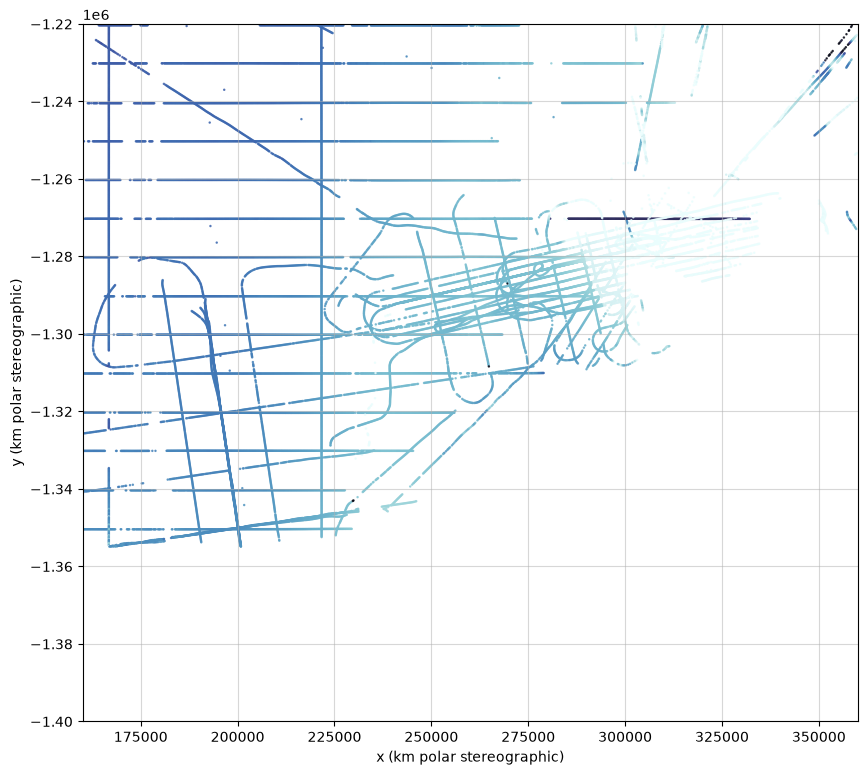

In [47]:
SUBSETTER = 10
fig, ax = plt.subplots(figsize = (10, 10))

# 2) thickness on top (draw second)
ax.scatter(
    bedmap123_ross_island_onshelf['x'][::SUBSETTER], 
    bedmap123_ross_island_onshelf['y'][::SUBSETTER], 
    c = bedmap123_ross_island_onshelf['t'][::SUBSETTER], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

# Preprocessing step 3: Crop at x = 300_000 to match Steward et al. 2019

In [48]:
bedmap123_ross_island_onshelf_cut = bedmap123_ross_island_onshelf[bedmap123_ross_island_onshelf["x"] < 300_000]

### Load MODIS for background

In [49]:
# tensor format so leave as is
modis_ross = torch.load("/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid_no_ocean.pt", weights_only = False)

# Replace zeroes with NaN for ocean mask (last dim is values)
modis_ross[2][modis_ross[2] == 0] = np.nan
modis_ross[2]

tensor([[16016., 16016., 16024.,  ..., 14608., 14512., 14352.],
        [16024., 16024., 16024.,  ..., 14704., 14600., 14400.],
        [16032., 16024., 16024.,  ..., 14832., 14712., 14464.],
        ...,
        [   nan,    nan,    nan,  ...,    nan,    nan,    nan],
        [   nan,    nan,    nan,  ...,    nan,    nan,    nan],
        [   nan,    nan,    nan,  ...,    nan,    nan,    nan]])

# Preprocessing step 4: Remove outliers

## 4.1: Remove single extreme values

In [50]:
# Inspect outliers
rm1_removal_candidates = bedmap123_ross_island_onshelf_cut[bedmap123_ross_island_onshelf_cut["t_fa"] > 500]
rm1_removal_candidates

,lon,lat,x,y,s,t,b,b_inferred,source,trajectory_id,trace_id,t_fa,VX,VY,SPEED
86420,167.270756,-77.869491,291461.427083,-1.290245e+06,548.159523,511.155908,37.003615,True,LDEO_2015_ROSETTA_AIR_BM3.csv,L850,-9999,501.155908,98.516103,39.956495,106.310602
86421,167.270094,-77.869460,291477.084709,-1.290245e+06,1130.838468,641.001254,489.837214,True,LDEO_2015_ROSETTA_AIR_BM3.csv,L850,-9999,631.001254,98.523762,39.958120,106.318310
86422,167.269432,-77.869429,291492.744375,-1.290245e+06,1130.826148,717.452107,413.374041,True,LDEO_2015_ROSETTA_AIR_BM3.csv,L850,-9999,707.452107,98.531417,39.959745,106.326014
146655,168.218199,-77.876700,269925.385986,-1.294113e+06,985.740000,728.750000,-728.750000,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2011356_MIS_JKB2e_Y35a,-9999,718.750000,71.371399,-48.955786,86.547939
150108,168.320642,-77.908416,266905.998488,-1.291183e+06,978.600000,726.340000,-726.340000,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2011356_MIS_JKB2e_Y37a,-9999,716.340000,69.898208,-100.751667,122.624051
153505,168.166043,-77.940760,269660.542532,-1.286981e+06,930.140000,692.220000,-692.220000,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2011357_MIS_JKB2e_Y43a,-9999,682.220000,78.441472,-106.437402,132.219457
153506,168.165727,-77.940581,269671.671843,-1.286999e+06,929.980000,692.120000,-692.120000,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2011357_MIS_JKB2e_Y43a,-9999,682.120000,78.471576,-106.179789,132.030057
183011,168.556828,-77.759065,264835.740523,-1.308350e+06,741.220000,592.920000,-592.920000,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2012318_WLB_JKB2h_X21a,-9999,582.920000,22.063980,-15.642090,27.046149
183012,168.556799,-77.758859,264840.892339,-1.308372e+06,741.490000,593.190000,-593.190000,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2012318_WLB_JKB2h_X21a,-9999,583.190000,22.088698,-15.552718,27.014766
183013,168.556765,-77.758653,264846.158358,-1.308394e+06,741.770000,593.930000,-593.930000,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2012318_WLB_JKB2h_X21a,-9999,583.930000,22.113880,-15.462868,26.983772


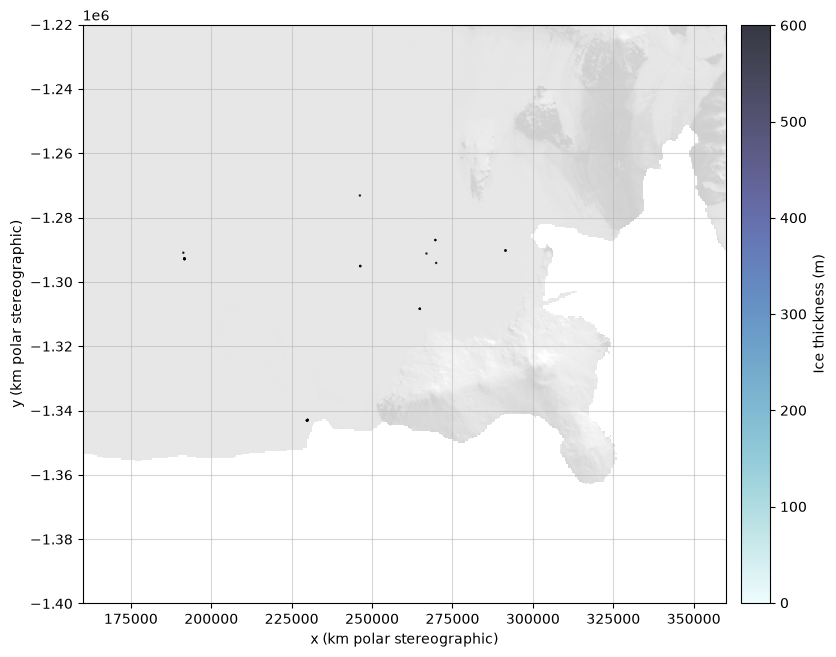

In [51]:
MODIS_background = True

fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    rm1_removal_candidates['x'], 
    rm1_removal_candidates['y'], 
    c = rm1_removal_candidates['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [52]:
bedmap123_ross_island_onshelf_cut_rm1 = bedmap123_ross_island_onshelf_cut[bedmap123_ross_island_onshelf_cut["t_fa"] < 500]

## 4.2: Inspect by source

In [53]:
bedmap123_ross_island_onshelf_cut_rm1["source"].value_counts()

source
UTIG_2010_ICECAP_AIR_BM3.csv       132552
LDEO_2015_ROSETTA_AIR_BM3.csv      103585
NASA_2011_ICEBRIDGE_AIR_BM2.csv      2744
BEDMAP1_1966-2000_AIR_BM1.csv         190
Name: count, dtype: int64

In [54]:
# Generate subsets for visualisation
bedmap123_ross_island_onshelf_cut_rm1_bm1 = bedmap123_ross_island_onshelf_cut_rm1[bedmap123_ross_island_onshelf_cut_rm1["source"] == "BEDMAP1_1966-2000_AIR_BM1.csv"]
bedmap123_ross_island_onshelf_cut_rm1_utig = bedmap123_ross_island_onshelf_cut_rm1[bedmap123_ross_island_onshelf_cut_rm1["source"] == "UTIG_2010_ICECAP_AIR_BM3.csv"]
bedmap123_ross_island_onshelf_cut_rm1_nasa = bedmap123_ross_island_onshelf_cut_rm1[bedmap123_ross_island_onshelf_cut_rm1["source"] == "NASA_2011_ICEBRIDGE_AIR_BM2.csv"]
bedmap123_ross_island_onshelf_cut_rm1_ldeo = bedmap123_ross_island_onshelf_cut_rm1[bedmap123_ross_island_onshelf_cut_rm1["source"] == "LDEO_2015_ROSETTA_AIR_BM3.csv"]

## Visualise Bedmap1 only

Does not conflict much but overlaps with other surveys so we may remove due to age.

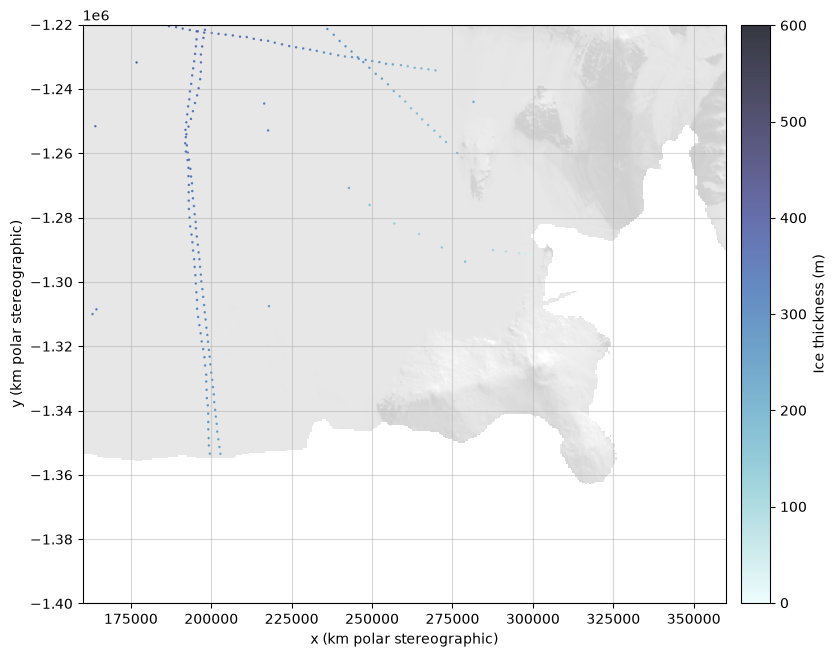

In [55]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_onshelf_cut_rm1_bm1['x'], 
    bedmap123_ross_island_onshelf_cut_rm1_bm1['y'], 
    c = bedmap123_ross_island_onshelf_cut_rm1_bm1['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

# NASA

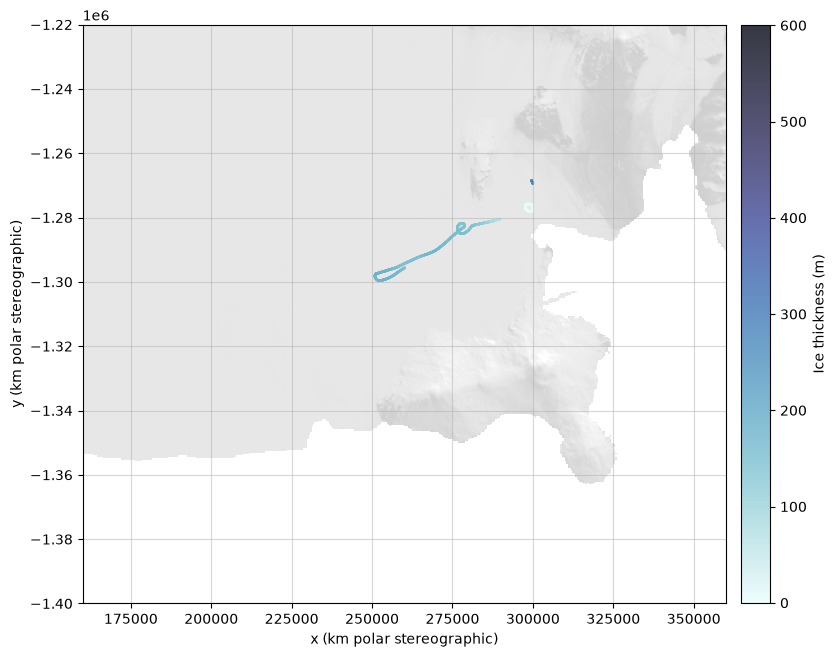

In [56]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_onshelf_cut_rm1_nasa['x'], 
    bedmap123_ross_island_onshelf_cut_rm1_nasa['y'], 
    c = bedmap123_ross_island_onshelf_cut_rm1_nasa['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [57]:
rm2_removal_candidates = bedmap123_ross_island_onshelf_cut_rm1[
    (bedmap123_ross_island_onshelf_cut_rm1["source"] == "NASA_2011_ICEBRIDGE_AIR_BM2.csv") &
    (bedmap123_ross_island_onshelf_cut_rm1["t_fa"] > 200) & 
    (bedmap123_ross_island_onshelf_cut_rm1["x"] > 290_000)]

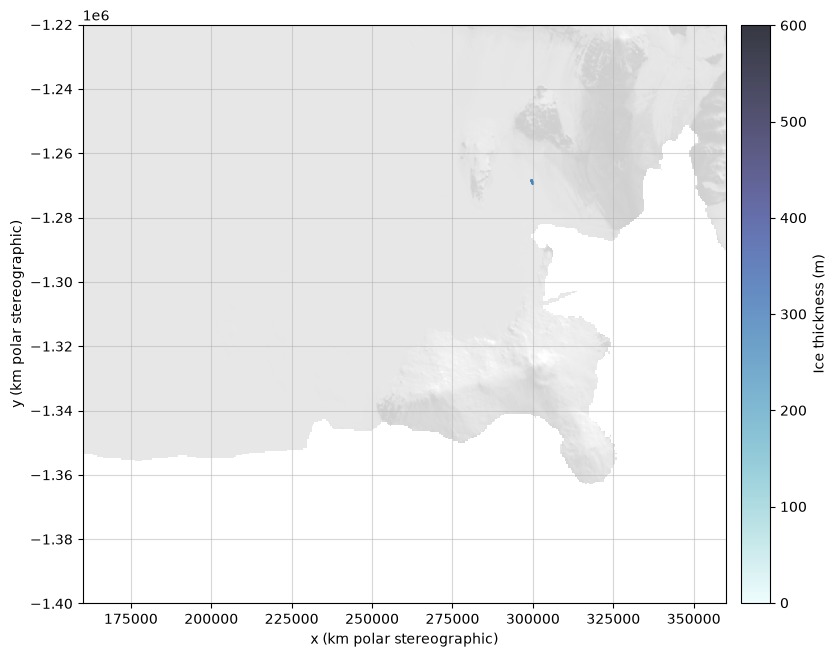

In [58]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    rm2_removal_candidates['x'], 
    rm2_removal_candidates['y'], 
    c = rm2_removal_candidates['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [59]:
bedmap123_ross_island_onshelf_cut_rm2 = bedmap123_ross_island_onshelf_cut_rm1[
    ~(
    (bedmap123_ross_island_onshelf_cut_rm1["source"] == "NASA_2011_ICEBRIDGE_AIR_BM2.csv") &
    (bedmap123_ross_island_onshelf_cut_rm1["t_fa"] > 200) & 
    (bedmap123_ross_island_onshelf_cut_rm1["x"] > 290_000)
    )]

# UTIG

Step RM1 removed some of the oddly placed starting points

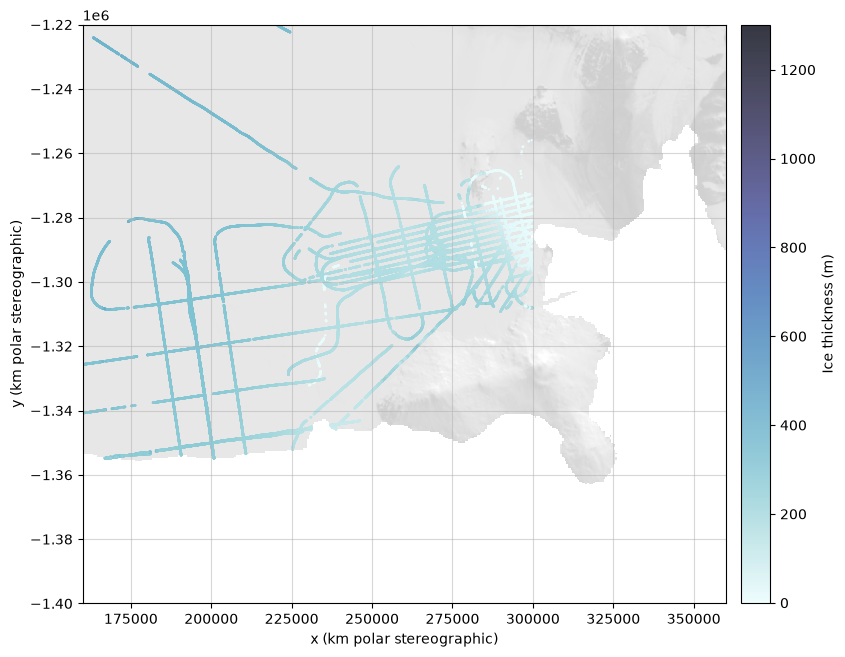

In [60]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) SMB on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_onshelf_cut_rm1_utig['x'], 
    bedmap123_ross_island_onshelf_cut_rm1_utig['y'], 
    c = bedmap123_ross_island_onshelf_cut_rm1_utig['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 1300 # saturate at 1200
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [61]:
rm3_removal_candidates = bedmap123_ross_island_onshelf_cut_rm2[
    (bedmap123_ross_island_onshelf_cut_rm2["source"] == "UTIG_2010_ICECAP_AIR_BM3.csv") & 
    (bedmap123_ross_island_onshelf_cut_rm2["t_fa"] < 10) &
    (bedmap123_ross_island_onshelf_cut_rm2["x"] < 285_000)]

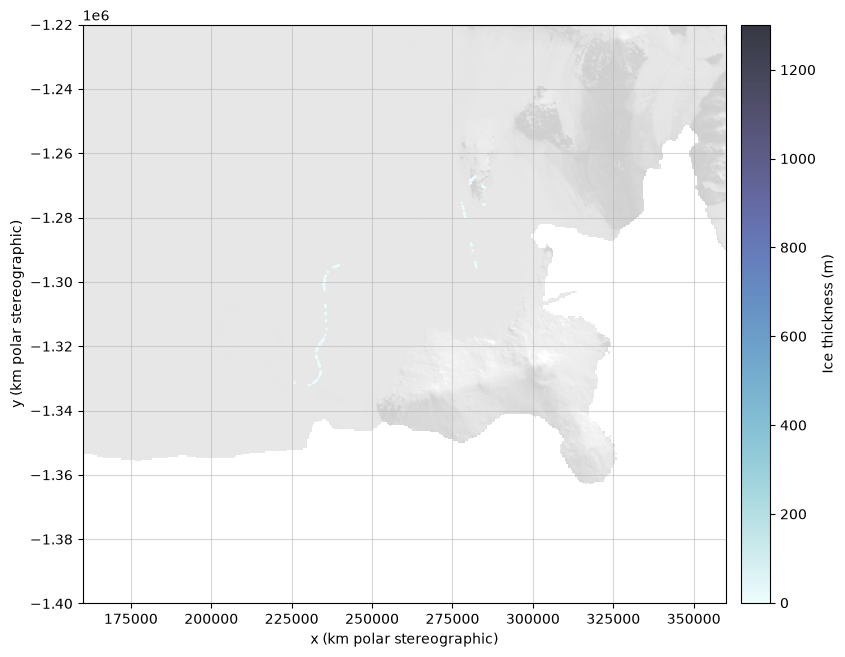

In [62]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) SMB on top (draw second)
sc =ax.scatter(
    rm3_removal_candidates['x'], 
    rm3_removal_candidates['y'], 
    c = rm3_removal_candidates['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 1300 # saturate at 1200
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [63]:
# Remove
bedmap123_ross_island_onshelf_cut_rm3 = bedmap123_ross_island_onshelf_cut_rm2[
    ~(
    (bedmap123_ross_island_onshelf_cut_rm2["source"] == "UTIG_2010_ICECAP_AIR_BM3.csv") & 
    (bedmap123_ross_island_onshelf_cut_rm2["t_fa"] < 10) &
    (bedmap123_ross_island_onshelf_cut_rm2["x"] < 285_000)
    )]

# LDEO

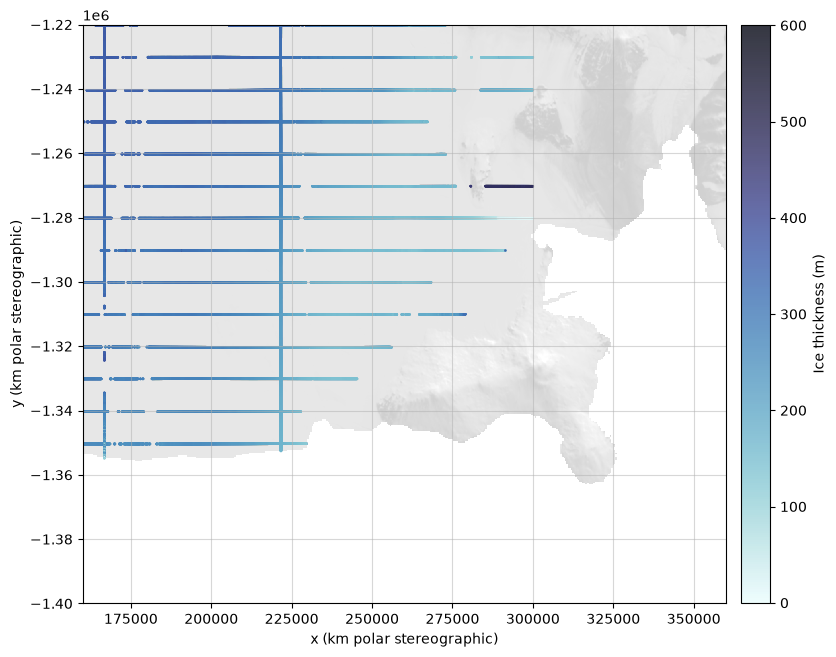

In [64]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_onshelf_cut_rm1_ldeo['x'], 
    bedmap123_ross_island_onshelf_cut_rm1_ldeo['y'], 
    c = bedmap123_ross_island_onshelf_cut_rm1_ldeo['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

Note: The dark patch disagrees with other surveys

In [65]:
rm4_removal_candidates = bedmap123_ross_island_onshelf_cut_rm3[
    (bedmap123_ross_island_onshelf_cut_rm3["source"] == "LDEO_2015_ROSETTA_AIR_BM3.csv") & 
    (bedmap123_ross_island_onshelf_cut_rm3["x"] > 275_000) &
    (bedmap123_ross_island_onshelf_cut_rm3["y"] < -1_260_000) &
    (bedmap123_ross_island_onshelf_cut_rm3["y"] > -1_280_000)]

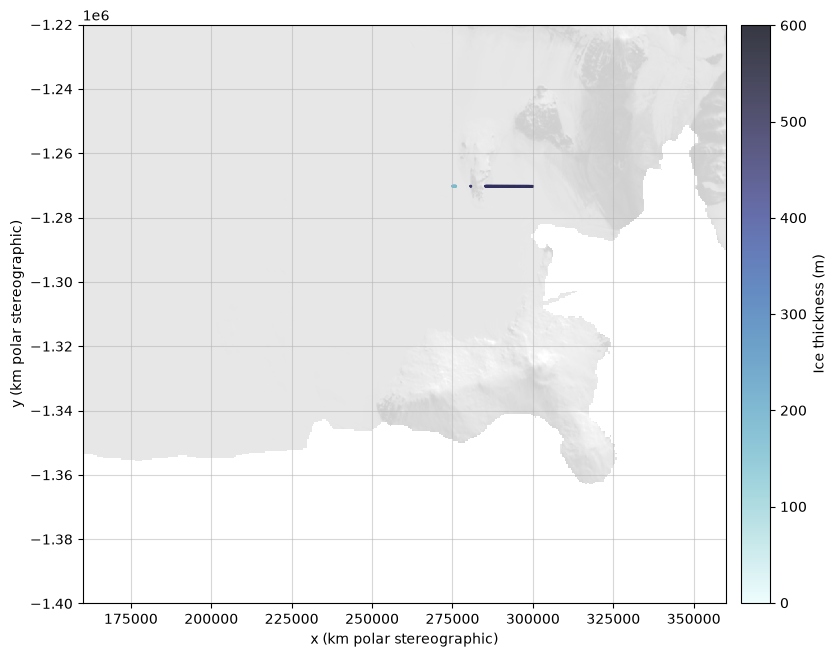

In [66]:
fig, ax = plt.subplots(figsize = (10, 10))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    rm4_removal_candidates['x'], 
    rm4_removal_candidates['y'], 
    c = rm4_removal_candidates['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

In [67]:
bedmap123_ross_island_onshelf_cut_rm4 = bedmap123_ross_island_onshelf_cut_rm3[
    ~(
    (bedmap123_ross_island_onshelf_cut_rm3["source"] == "LDEO_2015_ROSETTA_AIR_BM3.csv") & 
    (bedmap123_ross_island_onshelf_cut_rm3["x"] > 275_000) &
    (bedmap123_ross_island_onshelf_cut_rm3["y"] < -1_260_000) &
    (bedmap123_ross_island_onshelf_cut_rm3["y"] > -1_280_000)
    )]

# Final version

In [68]:
MODIS_background = True

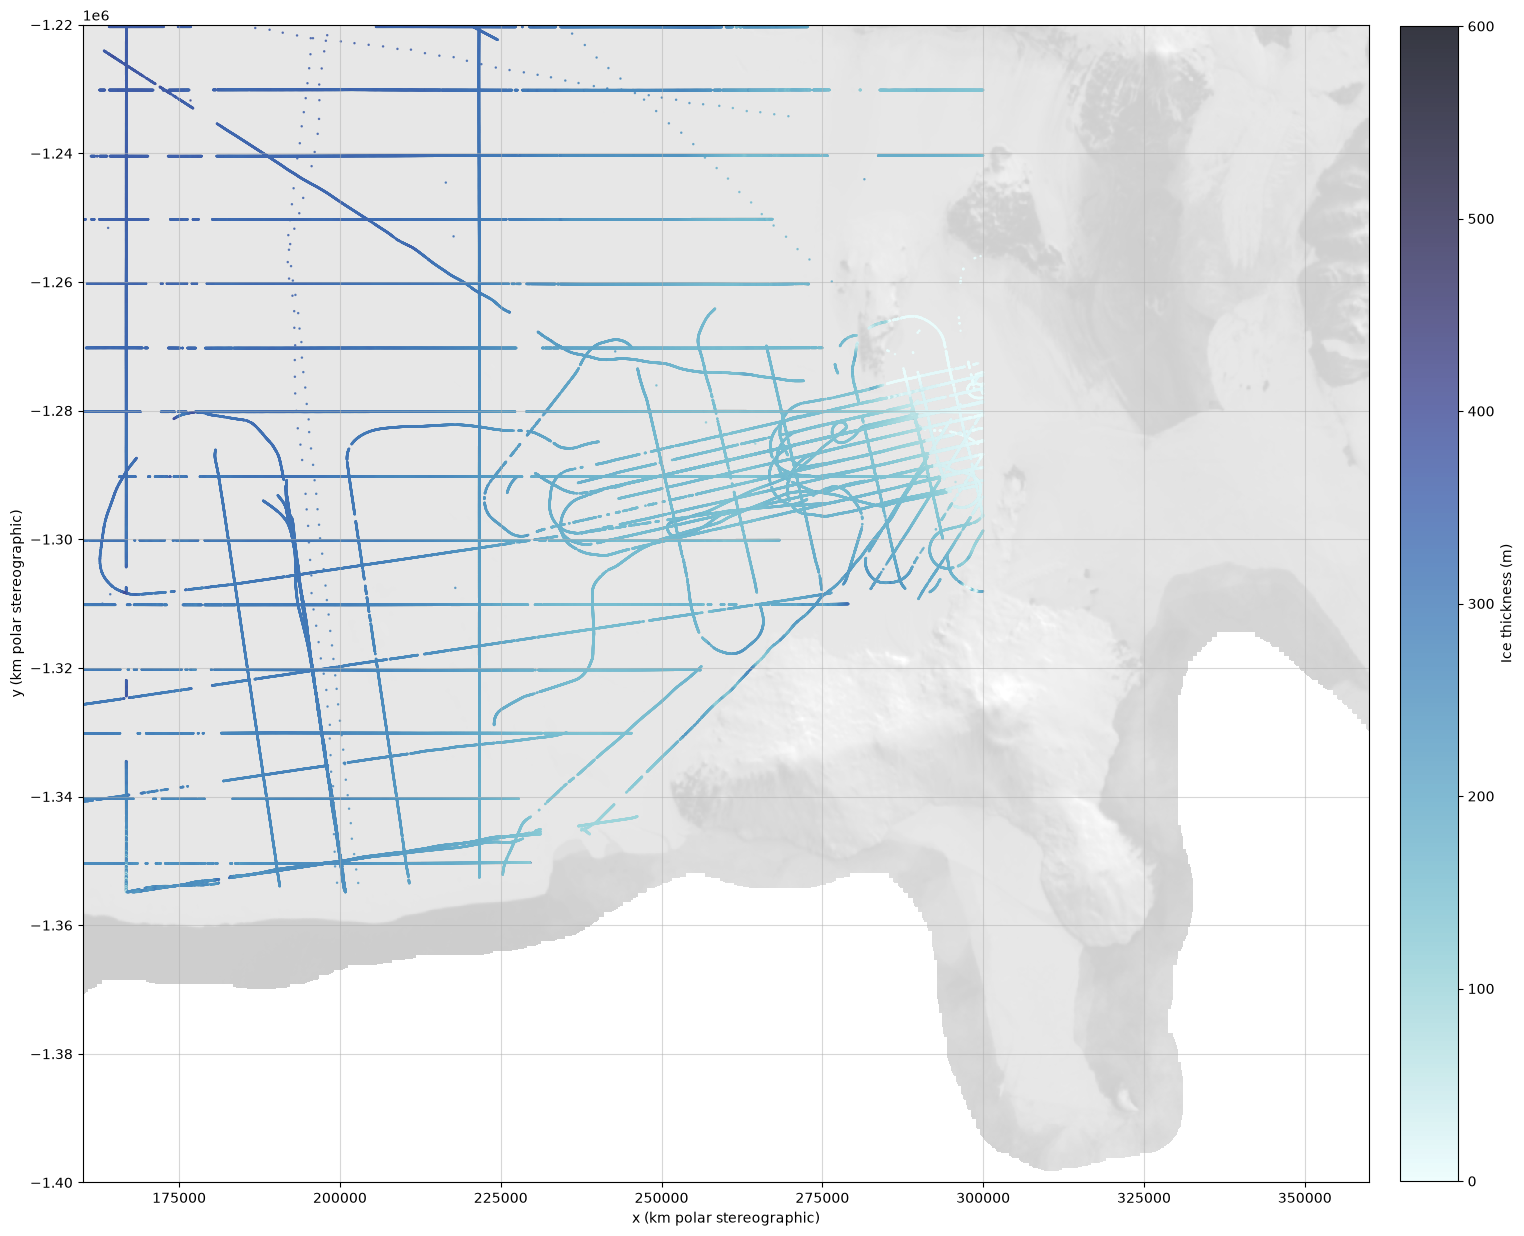

In [69]:
fig, ax = plt.subplots(figsize = (20, 20))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_onshelf_cut_rm4['x'], 
    bedmap123_ross_island_onshelf_cut_rm4['y'], 
    c = bedmap123_ross_island_onshelf_cut_rm4['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

# Save vis
plt.savefig("figures/ice_thickness_ross_island_full_modis.png", dpi = 300, bbox_inches = 'tight')

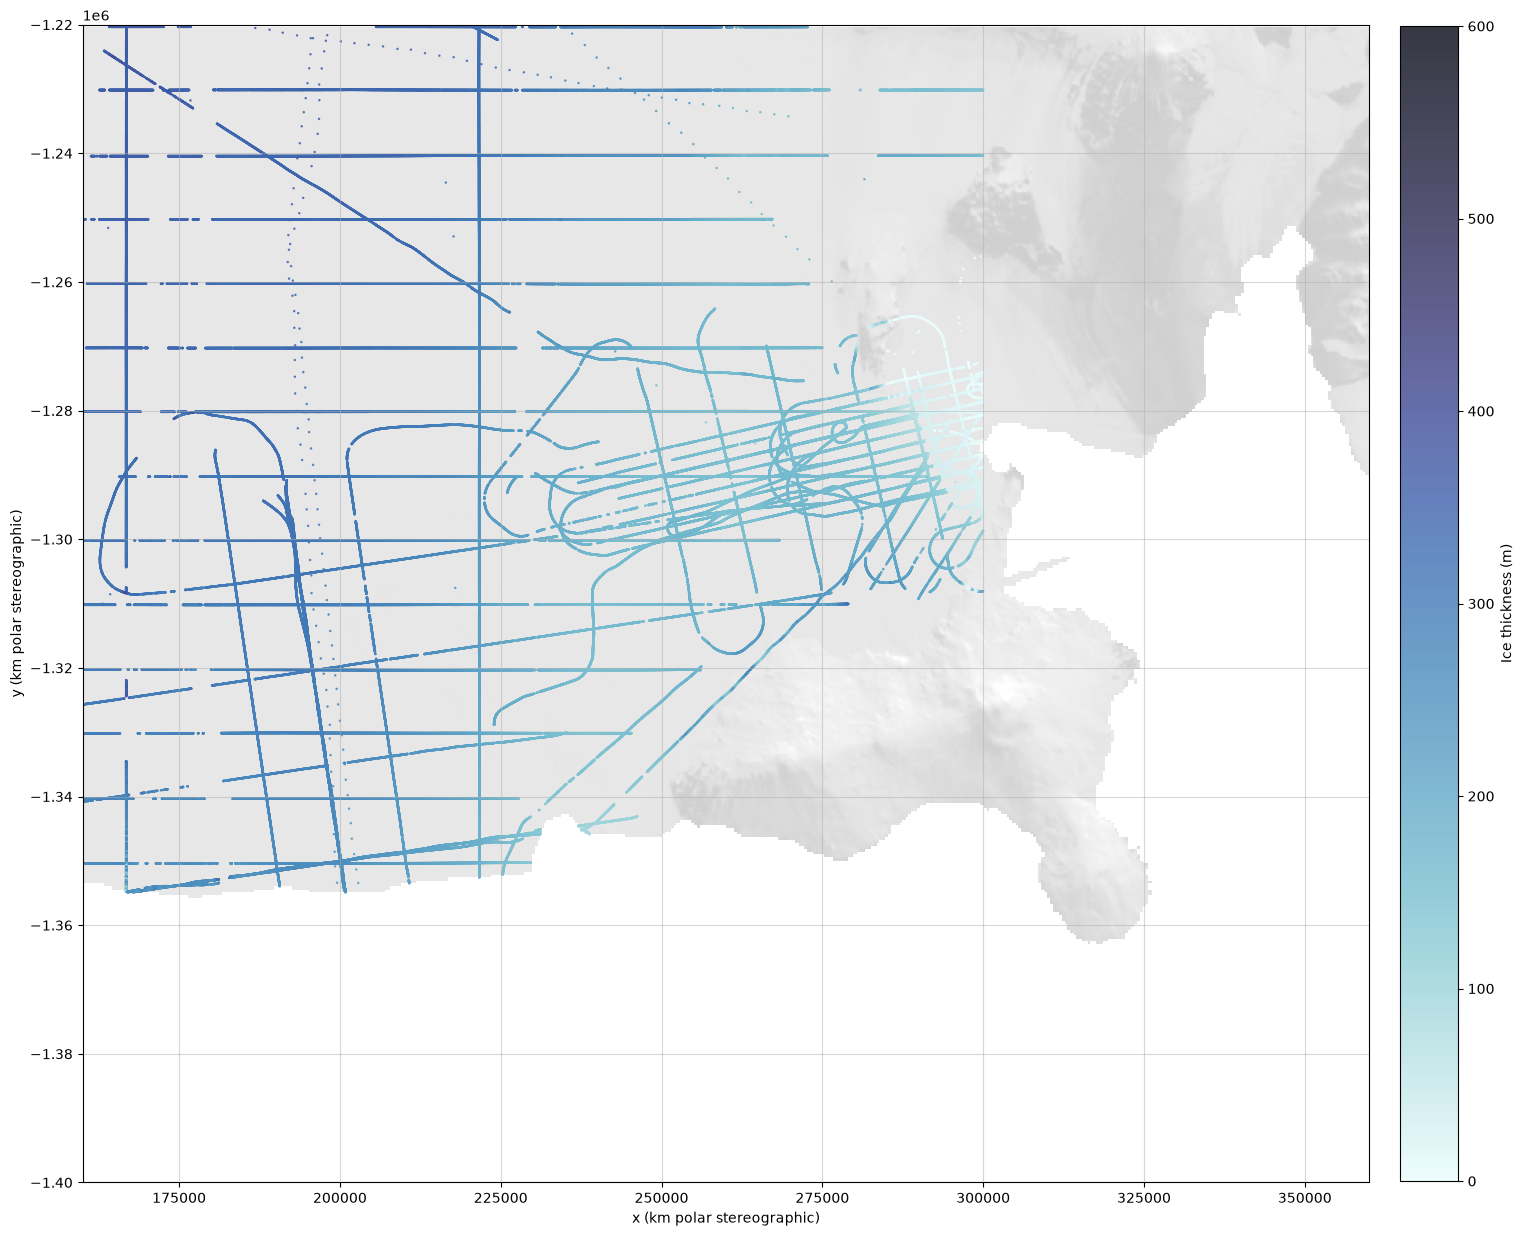

In [70]:
fig, ax = plt.subplots(figsize = (20, 20))

# 1) MODIS as background (draw first)
if MODIS_background:
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

# 2) thickness on top (draw second)
sc = ax.scatter(
    bedmap123_ross_island_onshelf_cut_rm4['x'], 
    bedmap123_ross_island_onshelf_cut_rm4['y'], 
    c = bedmap123_ross_island_onshelf_cut_rm4['t'], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = cmocean.cm.ice_r,
    vmin = 0,
    vmax = 600 # saturate at 600
    )

cbar = fig.colorbar(sc, ax = ax, pad = 0.02, shrink = 0.75)
cbar.set_label("Ice thickness (m)")

ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

# Optional: label axes to clarify units
ax.set_xlabel("x (km polar stereographic)")
ax.set_ylabel("y (km polar stereographic)")

ax.set_aspect('equal')
ax.grid(True, alpha = 0.5)

# Save vis
plt.savefig("figures/ice_thickness_ross_island_full_modis_no_ocean.png", dpi = 300, bbox_inches = 'tight')

In [33]:
bedmap123_ross_island_onshelf_cut_rm4

,lon,lat,x,y,s,t,b,b_inferred,source,trajectory_id,trace_id,t_fa,VX,VY,SPEED
0,170.133300,-78.411670,216463.844340,-1.244552e+06,54.00,320.00,-815.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,296,-9999,310.00,13.039961,-641.885702,642.018142
1,169.183300,-78.133330,242801.567307,-1.270798e+06,35.00,218.00,-920.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,297,-9999,208.00,48.095359,-506.675262,508.952832
2,168.950000,-78.075000,249201.416991,-1.276084e+06,31.00,156.00,-902.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,298,-9999,146.00,52.852511,-477.402828,480.319527
3,168.666700,-78.010000,256910.452033,-1.281834e+06,23.00,123.00,-887.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,299,-9999,113.00,59.210634,-412.069224,416.301506
4,168.366700,-77.966670,264577.987681,-1.285131e+06,26.00,111.00,-836.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,300,-9999,101.00,65.926850,-180.952293,192.587855
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
281359,171.567977,-77.443587,200825.331451,-1.354747e+06,-9.90,244.31,-254.21,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2013014_CLH_JKB2h_X18e,-9999,234.31,224.511314,-753.736043,786.462557
281360,171.567976,-77.443384,200828.626940,-1.354769e+06,-10.67,243.83,-254.49,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2013014_CLH_JKB2h_X18e,-9999,233.83,224.564998,-753.739089,786.480803
281361,171.567975,-77.443177,200831.986901,-1.354791e+06,-11.05,243.56,-254.61,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2013014_CLH_JKB2h_X18e,-9999,233.56,224.620634,-753.742852,786.500296
281362,171.567974,-77.442973,200835.298512,-1.354813e+06,-11.32,243.44,-254.77,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2013014_CLH_JKB2h_X18e,-9999,233.44,224.676350,-753.747208,786.520385


# Export

In [36]:
bedmap123_ross_island_onshelf_cut_rm4.to_csv("data/bedmap123_ross_island_cleaned_240k.csv", index = False)